# Description

Training for analyzing Octopus-slabs database with Pandas


# Page usage

* Checking how many entries we have with a certain filter.  


# Loading library

In [1]:
import pandas as pd
import octopus_slabs
from octopus_slabs.Libs.libPlotting import IndexFunctional
import os
import matplotlib.pyplot as plt
OctopusData=os.environ["QuantumLaPruns"]
OctopusSources=os.environ["QuantumLaPsources"]
print(OctopusData, OctopusSources)

/home/thibault.derrien/Documents/octopus.data /home/thibault.derrien/Documents/octopus-slabs


# Going to the folder containing the database

In [2]:
# Localhost
# DatabasePath=OctopusData+"/03-Bulk3D/Si-1x1x1-k-24x24x1-Mesh0.434637008855-Mesh0.434637008855-T0e0-TB09/SingleColorSummary"

# BIATRI-SRV TB09 from backups (Draco, etc)
# DatabasePath=OctopusData+"/03-Bulk3D/01-ImportingTB09"

DatabasePath=OctopusData+"/03-Bulk3D/"
%cd $DatabasePath

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D


# Database loading and quick analysis

In [3]:
data=pd.read_csv("SiComplete-2021-06-14-BiatriSrv-v2.1.2-WithoutUnfinishedBicolors-WithToleranceOnField-WithAllTB09.csv", "\t", header=2)
datafull=data
data.describe(include="all")
data.dtypes


#JobID                          float64
RunDate                         float64
kgrid                           float64
realmesh                        float64
lambda1                         float64
tau1                            float64
Efield1                         float64
PolarizationAngle               float64
CEP1                            float64
lambda2                         float64
tau2                            float64
Efield2                         float64
CEP2                            float64
delay                           float64
CrossPolar                      float64
TheoryLevel                     float64
InducedFields                   float64
ProbeFieldAmplitude_au          float64
ProbeFieldDelay_s               float64
Functional                      float64
FrozenHxc                       float64
MoveIon                         float64
NeMax                           float64
NeFinal                         float64
VirtualOscillations             float64


# Database filtering

In [4]:
data=datafull
data=data[data.Functional==IndexFunctional["LDA"]] #0: LDA, #3: TB09, #2: GGA, #1: MGGA
data

,#JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
0,5905896.0,20180912.0,24.0,0.434637,1.060000e-06,2.000000e-14,1.000000e+08,0.000000,0.0,1.060000e-06,...,0.000014,0.000007,5.688517e+10,2.346824e+21,9.408130e+34,1.173412e+35,3.0,2.0,3850.00,973.001435
1,4802615.0,20180508.0,24.0,0.434637,8.000000e-07,2.000000e-14,8.000000e+08,0.000000,0.0,8.000000e-07,...,0.011121,0.037806,-2.567970e+13,2.810220e+26,1.404822e+40,1.405110e+40,3.0,2.0,2262.50,937.147441
2,5882467.0,20180909.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,1.030000e-06,...,0.008671,0.042221,-3.133202e+14,4.712362e+26,1.570724e+40,1.570787e+40,3.0,2.0,3087.50,1350.561171
3,5882393.0,20180904.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,1.600000e-06,...,0.013881,0.041614,-1.059148e+14,4.433284e+26,1.477840e+40,1.477761e+40,3.0,2.0,3175.00,1350.561171
4,5882390.0,20180904.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,1.600000e-06,...,0.007297,0.030018,-4.980174e+13,2.513958e+26,8.378722e+39,8.379861e+39,3.0,2.0,3262.50,1350.561171
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2225,360358.0,20210224.0,24.0,0.434637,3.200000e-06,3.000000e-14,3.000000e+09,0.000000,0.0,3.200000e-06,...,0.000000,3.668076,-2.871279e+15,8.836782e+27,2.946116e+41,2.945594e+41,3.0,2.0,4807.50,1681.521115
2226,441932.0,20210429.0,24.0,0.434637,2.656000e-06,1.394500e-14,1.050000e+10,0.000000,0.0,2.656000e-06,...,0.000000,78.535969,2.231728e+15,8.493147e+28,6.090377e+42,6.090460e+42,1.0,0.0,3266.25,1153.010893
2227,441931.0,20210429.0,24.0,0.434637,2.656000e-06,1.394500e-14,3.000000e+09,0.000000,0.0,2.656000e-06,...,0.000000,0.477183,-1.110208e+15,1.973214e+27,1.416821e+41,1.414998e+41,1.0,0.0,3266.25,1153.010893
2228,441962.0,20210429.0,24.0,0.434637,2.656000e-06,1.394500e-14,3.000000e+09,0.785398,0.0,2.656000e-06,...,0.000000,0.314102,-8.768611e+14,2.479292e+27,1.779908e+41,1.777907e+41,1.0,0.0,3266.25,1153.010893


In [6]:
#data=data[data.CEP1==0]; 
#data=data[data.STH==3]; 
data=data[data.InducedFields==0]
data

,#JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
0,5905896.0,20180912.0,24.0,0.434637,1.060000e-06,2.000000e-14,1.000000e+08,0.000000,0.0,1.060000e-06,...,0.000014,0.000007,5.688517e+10,2.346824e+21,9.408130e+34,1.173412e+35,3.0,2.0,3850.00,973.001435
1,4802615.0,20180508.0,24.0,0.434637,8.000000e-07,2.000000e-14,8.000000e+08,0.000000,0.0,8.000000e-07,...,0.011121,0.037806,-2.567970e+13,2.810220e+26,1.404822e+40,1.405110e+40,3.0,2.0,2262.50,937.147441
2,5882467.0,20180909.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,1.030000e-06,...,0.008671,0.042221,-3.133202e+14,4.712362e+26,1.570724e+40,1.570787e+40,3.0,2.0,3087.50,1350.561171
3,5882393.0,20180904.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,1.600000e-06,...,0.013881,0.041614,-1.059148e+14,4.433284e+26,1.477840e+40,1.477761e+40,3.0,2.0,3175.00,1350.561171
4,5882390.0,20180904.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,1.600000e-06,...,0.007297,0.030018,-4.980174e+13,2.513958e+26,8.378722e+39,8.379861e+39,3.0,2.0,3262.50,1350.561171
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2225,360358.0,20210224.0,24.0,0.434637,3.200000e-06,3.000000e-14,3.000000e+09,0.000000,0.0,3.200000e-06,...,0.000000,3.668076,-2.871279e+15,8.836782e+27,2.946116e+41,2.945594e+41,3.0,2.0,4807.50,1681.521115
2226,441932.0,20210429.0,24.0,0.434637,2.656000e-06,1.394500e-14,1.050000e+10,0.000000,0.0,2.656000e-06,...,0.000000,78.535969,2.231728e+15,8.493147e+28,6.090377e+42,6.090460e+42,1.0,0.0,3266.25,1153.010893
2227,441931.0,20210429.0,24.0,0.434637,2.656000e-06,1.394500e-14,3.000000e+09,0.000000,0.0,2.656000e-06,...,0.000000,0.477183,-1.110208e+15,1.973214e+27,1.416821e+41,1.414998e+41,1.0,0.0,3266.25,1153.010893
2228,441962.0,20210429.0,24.0,0.434637,2.656000e-06,1.394500e-14,3.000000e+09,0.785398,0.0,2.656000e-06,...,0.000000,0.314102,-8.768611e+14,2.479292e+27,1.779908e+41,1.777907e+41,1.0,0.0,3266.25,1153.010893


In [7]:
data=data.sort_values(["lambda1", "tau1", "Efield1", "Efield2", "PolarizationAngle", "kgrid", "realmesh"], ascending=True)
datafull=data

In [8]:
datafull

,#JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
164,5109637.0,20180601.0,24.0,0.434637,2.000000e-07,2.000000e-14,1.000000e+08,0.0,0.0,2.000000e-07,...,0.000755,0.009809,-2.583857e+11,3.957254e+25,1.973568e+39,1.978627e+39,3.0,2.0,3812.5,854.407455
1470,8715191.0,20190625.0,24.0,0.434637,2.000000e-07,2.000000e-14,5.000000e+08,0.0,0.0,2.000000e-07,...,0.017231,0.231439,-7.046549e+12,9.323506e+26,4.661432e+40,4.661753e+40,3.0,2.0,3125.0,854.407455
1525,8918119.0,20190708.0,24.0,0.434637,2.000000e-07,2.000000e-14,7.500000e+08,0.0,0.0,2.000000e-07,...,0.036709,0.483535,-9.950841e+12,1.940461e+27,9.701183e+40,9.702303e+40,3.0,2.0,3125.0,854.407455
313,5027620.0,20180524.0,24.0,0.434637,2.000000e-07,2.000000e-14,1.000000e+09,0.0,0.0,2.000000e-07,...,0.062334,0.776664,5.249025e+12,3.099319e+27,1.549393e+41,1.549659e+41,3.0,2.0,2975.0,854.407455
1415,8918121.0,20190709.0,24.0,0.434637,2.000000e-07,2.000000e-14,1.500000e+09,0.0,0.0,2.000000e-07,...,0.110365,1.334319,-1.315329e+13,5.230000e+27,2.614998e+41,2.615000e+41,3.0,2.0,3125.0,854.407455
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1405,10050046.0,20191101.0,24.0,0.434637,4.100000e-06,2.000000e-14,5.000000e+08,0.0,0.0,4.100000e-06,...,0.000855,0.000040,4.772506e+13,4.989094e+21,2.465914e+35,2.494547e+35,3.0,2.0,3750.0,1392.217365
1740,17608855.0,20200127.0,24.0,0.434637,6.400000e-06,6.000000e-14,5.000000e+08,0.0,0.0,6.400000e-06,...,0.000209,0.000037,9.126449e+13,4.887741e+21,7.342516e+34,8.146234e+34,3.0,2.0,7750.0,3363.042231
1737,17638129.0,20200127.0,24.0,0.434637,6.400000e-06,6.000000e-14,7.500000e+08,0.0,0.0,6.400000e-06,...,0.000481,0.000141,7.494698e+13,7.795684e+23,1.286704e+37,1.299281e+37,3.0,2.0,7625.0,3363.042231
1713,17608858.0,20200127.0,24.0,0.434637,6.400000e-06,6.000000e-14,1.000000e+09,0.0,0.0,6.400000e-06,...,0.000871,0.002872,-5.717343e+12,1.598631e+25,2.664830e+38,2.664386e+38,3.0,2.0,7500.0,3363.042231


In [10]:
datatmp=datafull
# datatmp=data[data.PolarizationAngle>0]
datatmp=datatmp[datatmp.lambda1==515e-9]
datatmp=datatmp[datatmp.Efield2==0]
datatmp=datatmp[datatmp.CEP1==0]
# datatmp=datatmp[datatmp.STH==3]
datatmp=datatmp[datatmp.tau1==20e-15]
data2 = datatmp

Efield1=datatmp.Efield1
# Efield2=datatmp.Efield2
# JobID=datatmp.JobID
RunDate_t=datatmp.RunDate
Nexc=datatmp.N_exc_afterpulse
Wpi=datatmp.Wpi
Wpi_afterpulse=datatmp.Wpi_afterpulse
tau1=datatmp.tau1
AbsEnergy=datatmp.Energy_afterpulse_eV
PolarizationAngle=datatmp.PolarizationAngle
STH=datatmp.STH
# plt.loglog(Efield, Wpi, "v")
# plt.semilogx(JobID, RunDate_t)
# datafield1=datatmp[datatmp.Efield1==3E9]
# datafield2=datatmp[datatmp.Efield1==9E9]

In [11]:
datatmp

,#JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
231,5109649.0,20180601.0,24.0,0.434637,5.150000e-07,2.000000e-14,1.000000e+08,0.0,0.0,5.150000e-07,...,0.000371,0.000694,-8.547189e+11,5.819965e+24,2.856741e+38,2.909983e+38,3.0,2.0,3762.5,897.845948
1247,8715209.0,20190627.0,24.0,0.434637,5.150000e-07,2.000000e-14,5.000000e+08,0.0,0.0,5.150000e-07,...,0.009479,0.019275,-1.380385e+12,1.476014e+26,7.368815e+39,7.380070e+39,3.0,2.0,3125.0,897.845948
1431,8918132.0,20190709.0,24.0,0.434637,5.150000e-07,2.000000e-14,7.500000e+08,0.0,0.0,5.150000e-07,...,0.020994,0.053554,1.571800e+13,3.723373e+26,1.860877e+40,1.861686e+40,3.0,2.0,3000.0,897.845948
1097,5027635.0,20180525.0,24.0,0.434637,5.150000e-07,2.000000e-14,1.000000e+09,0.0,0.0,5.150000e-07,...,0.033906,0.121628,-4.817450e+13,7.791164e+26,3.895180e+40,3.895582e+40,3.0,2.0,2725.0,897.845948
1565,8918133.0,20190709.0,24.0,0.434637,5.150000e-07,2.000000e-14,1.500000e+09,0.0,0.0,5.150000e-07,...,0.076998,0.405591,9.559337e+13,2.278189e+27,1.138976e+41,1.139094e+41,3.0,2.0,2875.0,897.845948
1406,8649981.0,20190622.0,24.0,0.434637,5.150000e-07,2.000000e-14,2.000000e+09,0.0,0.0,5.150000e-07,...,0.142600,0.906773,1.581342e+14,4.755139e+27,2.377285e+41,2.377569e+41,3.0,2.0,3000.0,897.845948
1542,8715213.0,20190627.0,24.0,0.434637,5.150000e-07,2.000000e-14,3.000000e+09,0.0,0.0,5.150000e-07,...,0.273413,1.984661,2.258693e+14,9.288119e+27,4.641914e+41,4.644060e+41,3.0,2.0,3000.0,897.845948
1463,8715214.0,20190627.0,24.0,0.434637,5.150000e-07,2.000000e-14,4.000000e+09,0.0,0.0,5.150000e-07,...,0.372968,3.612577,2.309676e+14,1.508679e+28,7.541152e+41,7.543395e+41,3.0,2.0,2750.0,897.845948
127,5027636.0,20180525.0,24.0,0.434637,5.150000e-07,2.000000e-14,5.000000e+09,0.0,0.0,5.150000e-07,...,0.520124,6.042565,-3.677350e+14,2.197992e+28,1.097654e+42,1.098996e+42,3.0,2.0,2400.0,897.845948
1028,5027637.0,20180525.0,24.0,0.434637,5.150000e-07,2.000000e-14,1.000000e+10,0.0,0.0,5.150000e-07,...,1.247222,41.685514,-4.019898e+15,6.253307e+28,3.126264e+42,3.126654e+42,3.0,2.0,2112.5,897.845948


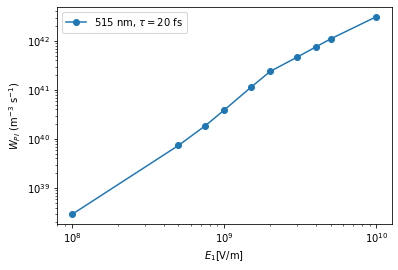

In [12]:
plt.figure()
plt.loglog(data2.Efield1, data2.Wpi_afterpulse, "-o", label=r"515 nm, $\tau=$20 fs")
plt.xlabel(r"$E_1$[V/m]")
plt.ylabel(r"$W_{PI}$ (m$^{-3}$ s$^{-1}$)")
plt.legend()